In [1]:
# Import needed libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
data = pd.read_csv("bike_sales_messy_dataset.csv")

In [2]:
# Preliminary Assessment

# Check shape
print(data.shape, "\n")



# Checking the data type, count and percentage of missing values
# of each column

def dataframe_access(df):
    # Column Data Types
    se_dtype = df.dtypes
    data_explore = pd.DataFrame(se_dtype, columns = ['Data Types'])


    # Missing values count (mvc)
    se_mvc = df.isnull().sum()


    # Missing values percentage (mvp)
    se_mvp = (df.isnull().mean() * 100).round(2)


    # Combining them into one table
    data_explore['Missing Cells'] = se_mvc
    data_explore['Missing Cells (%)'] = se_mvp
    result = data_explore.sort_values(by = 'Missing Cells', ascending = False)
    
    return result

dataframe_access(data)

(735000, 24) 



,Data Types,Missing Cells,Missing Cells (%)
Type of Bike,object,367465,50.00
Commute Distance,object,113003,15.37
Brand,object,106732,14.52
Color,object,82609,11.24
Marital Status,object,81684,11.11
Size,object,71608,9.74
Discount Applied,object,66216,9.01
Home Ownership,object,61112,8.31
Model,object,55929,7.61
Educational Level,object,33495,4.56


In [3]:
# Standardize the column name formats
data.columns = (data.columns
               .astype(str)
               .str.strip()
               .str.lower()
               .str.replace(" ", "_")
               )

data.columns

Index(['order_id', 'date_of_purchase', 'quantity_sold', 'total_revenue',
       'cost', 'profit', 'discount_applied', 'customer_age', 'gender',
       'marital_status', 'income', 'educational_level', 'occupation',
       'product_category', 'type_of_bike', 'model', 'color', 'size', 'brand',
       'commute_distance', 'home_ownership', 'number_of_cars',
       'number_of_children', 'purchased_or_not'],
      dtype='object')

In [4]:
# Assessing and displaying the duplicate records in the entire dataset

print('Number of Duplicate records:',data.duplicated().sum(), "\n")

data.loc[data.duplicated(keep = False), :].sort_values(by = list(data.columns)).head(10)

Number of Duplicate records: 35000 



,order_id,date_of_purchase,quantity_sold,total_revenue,cost,profit,discount_applied,customer_age,gender,marital_status,...,type_of_bike,model,color,size,brand,commute_distance,home_ownership,number_of_cars,number_of_children,purchased_or_not
31177,1,2020-10-19 16:46:05,1,3000.0,2059.55,940.45,0.3,66,Male,complicated,...,E-Bike,Speedster,blue,One Size,Trek,<1 mile,OWN,0,0,Yes
368823,1,2020-10-19 16:46:05,1,3000.0,2059.55,940.45,0.3,66,Male,complicated,...,E-Bike,Speedster,blue,One Size,Trek,<1 mile,OWN,0,0,Yes
328617,19,2025-11-24 02:06:26,1,1000.0,534.56,465.44,0,63,Mâle,S,...,e-bike,X1,Green,s,trek,unknown,NaN,0,3,Yes
329784,19,2025-11-24 02:06:26,1,1000.0,534.56,465.44,0,63,Mâle,S,...,e-bike,X1,Green,s,trek,unknown,NaN,0,3,Yes
203816,48,2021-08-21 16:30:09,4,280.0,142.58,137.42,0.15,50,man,D,...,NaN,NaN,White,One Size,Shimano,car,Mortgage,2,2,true
412536,48,2021-08-21 16:30:09,4,280.0,142.58,137.42,0.15,50,man,D,...,NaN,NaN,White,One Size,Shimano,car,Mortgage,2,2,true
323414,67,2025-07-21 07:06:28,several,45.0,31.07,13.93,0,38,she/her,Single,...,NaN,Brake Pad,Black,adjustable,generic,3-5 miles,other,1,twins,N
435732,67,2025-07-21 07:06:28,several,45.0,31.07,13.93,0,38,she/her,Single,...,NaN,Brake Pad,Black,adjustable,generic,3-5 miles,other,1,twins,N
299595,101,2020-06-10 08:05:08,1,500.0,301.72,198.28,0,19,Mâle,Married,...,Road,X1,blue,s,Bianchi,NaN,Rent,1,0,unknown
343665,101,2020-06-10 08:05:08,1,500.0,301.72,198.28,0,19,Mâle,Married,...,Road,X1,blue,s,Bianchi,NaN,Rent,1,0,unknown


In [5]:
# Make a copy of the dataset
dataset = data.copy()

# Remove the duplicate records; keeping only the first
# occurrence of any record that has duplicates.
dataset = dataset.loc[~dataset.duplicated(keep = 'first'),:]

# Check shape of final dataset
print(dataset.shape, "\n")

dataframe_access(dataset)

(700000, 24) 



,Data Types,Missing Cells,Missing Cells (%)
type_of_bike,object,350037,50.01
commute_distance,object,107611,15.37
brand,object,101641,14.52
color,object,78717,11.25
marital_status,object,77779,11.11
size,object,68149,9.74
discount_applied,object,63050,9.01
home_ownership,object,58294,8.33
model,object,53306,7.62
educational_level,object,31905,4.56


In [6]:
# Extract the dataset of Customer Demography, Behavior and Lifestyle
# Demography data: Age, Gender, Income, Marital Status, Educational Level, Number of Children 
# Lifestyle data: Commute Distance, Occupation, Home Ownership, Car Ownership, Income Level
# Behaviour data: Purchased or Not, Type of Cycling Interest (Commuter, Mountain Biker, Road Cyclist, Family Ride)

# Obtain the necessary column names
cols_CustDBL = ['order_id', 'date_of_purchase', 'customer_age', 'gender',
       'marital_status', 'income', 'educational_level', 'occupation',
       'product_category', 'type_of_bike', 'commute_distance', 'home_ownership', 
        'number_of_cars', 'number_of_children', 'purchased_or_not']

# Extract the data for the columns
data_CustDBL = dataset[cols_CustDBL]   #DBL --> Demography, Behavior and Lifestyle
data_CustDBL.columns

Index(['order_id', 'date_of_purchase', 'customer_age', 'gender',
       'marital_status', 'income', 'educational_level', 'occupation',
       'product_category', 'type_of_bike', 'commute_distance',
       'home_ownership', 'number_of_cars', 'number_of_children',
       'purchased_or_not'],
      dtype='object')

# Handling Columns

## CATEGORICAL COLUMNS

In [7]:
categorical_cols = ['gender','marital_status', 'educational_level', 'occupation',
                   'product_category', 'type_of_bike', 'commute_distance',
                   'home_ownership', 'purchased_or_not']


# Fill the missing data first
data_CustDBL[categorical_cols] = data_CustDBL[categorical_cols].fillna("Unknown")


# Ensure consistency of capitalization of the
# text values in each column of the dataframe.

for cols in categorical_cols:
    data_CustDBL[cols] = (data_CustDBL[cols]
                                 .astype(str)
                                 .str.strip()
                                 .str.title()
                    )

C:\Users\ugoch\anaconda3\lib\site-packages\pandas\core\frame.py:3191: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self[k1] = value[k2]
<ipython-input-7-6685fcb43656>:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL[cols] = (data_CustDBL[cols]


### Gender

In [8]:
# Show the unique values BEFORE mapping
print(data_CustDBL['gender'].unique(), "\n")

# Create a mapping
mapping_gender = {'Man' : 'Male/He/Him/Man', 
                  '♂' : 'Male/He/Him/Man', 
                  'Mail' : 'Male/He/Him/Man', 
                  'M' : 'Male/He/Him/Man', 
                  'He/Him' : 'Male/He/Him/Man', 
                  'Mâle' : 'Male/He/Him/Man',
                  'Male': 'Male/He/Him/Man',
                  '♀' : 'Female/She/Her/Woman', 
                  'F' : 'Female/She/Her/Woman', 
                  'She/Her' : 'Female/She/Her/Woman', 
                  'Woman' : 'Female/She/Her/Woman', 
                  'Fémale' : 'Female/She/Her/Woman',
                  'Female' : 'Female/She/Her/Woman',
                  'Prefer Not To Say' : 'Unspecified'
                    
}

# Apply the mapping
data_CustDBL['gender'] = data_CustDBL['gender'].map(mapping_gender).fillna(data_CustDBL['gender'])
      
# Show the unique values AFTER mapping
print(data_CustDBL['gender'].unique(), "\n")

['Non-Binary' 'Man' 'Female' 'Unknown' '♀' 'F' '♂' 'Mail' 'She/Her' 'M'
 'Prefer Not To Say' 'Woman' 'He/Him' 'Mâle' 'Male' 'Fémale'] 

['Non-Binary' 'Male/He/Him/Man' 'Female/She/Her/Woman' 'Unknown'
 'Unspecified'] 



<ipython-input-8-330a91a37754>:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['gender'] = data_CustDBL['gender'].map(mapping_gender).fillna(data_CustDBL['gender'])


### Marital Status

In [9]:
# Show the unique values BEFORE mapping
print(data_CustDBL['marital_status'].unique(), "\n")


# Create a mapping
mapping_marital = { 'D' : 'Divorced',
                    'S' : 'Single' ,
                    'Living Together' : 'Partnership',
                    'W' : 'Widowed' ,
                    'M' : 'Married'
    
}

# Apply the mapping
data_CustDBL['marital_status'] = data_CustDBL['marital_status'].map(mapping_marital).fillna(data_CustDBL['marital_status'])
      
# Show the unique values AFTER mapping
print(data_CustDBL['marital_status'].unique(), "\n")

['Married' 'Single' 'Widowed' 'D' 'S' 'Unknown' 'Living Together'
 'Complicated' 'W' 'Separated' 'M' 'Divorced'] 

['Married' 'Single' 'Widowed' 'Divorced' 'Unknown' 'Partnership'
 'Complicated' 'Separated'] 



<ipython-input-9-194c8f5e9a07>:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['marital_status'] = data_CustDBL['marital_status'].map(mapping_marital).fillna(data_CustDBL['marital_status'])


### Educational Level

In [10]:
# Show the unique values BEFORE mapping
print(data_CustDBL['educational_level'].unique(), "\n")


# Create a mapping
mapping_education = {   'Bs' : 'Bachelors',
                        "Bachelor'S" : 'Bachelors',
                        'Ba' : 'Bachelors',
                        'Bachelors':'Bachelors',
                        'PhD' : 'Doctorate' ,
                        'Doctorate' : 'Doctorate',
                        'Phd' : 'Doctorate' ,
                        'Dropout' : 'School Leaver' ,
                        'Ged' : 'High School/GED' ,
                        'Highschool' : 'High School/GED', 
                        'Hs' : 'High School/GED' ,
                        'High School' : 'High School/GED' ,
                        "Master'S" : 'Masters' ,
                        'Ma' : 'Masters' ,
                        'Ms' : 'Masters' ,
                        'Masters' : 'Masters' ,
                        'Some College' : 'College'
    
}

# Apply the mapping
data_CustDBL['educational_level'] = (data_CustDBL['educational_level']
                                     .map(mapping_education)
                                     .fillna(data_CustDBL['educational_level'])
                                    )
      
# Show the unique values AFTER mapping
print(data_CustDBL['educational_level'].unique(), "\n")

['Bs' 'Ged' 'Dropout' 'Masters' "Bachelor'S" 'Doctorate' 'Ba' 'Bachelors'
 "Master'S" 'Ma' 'Elementary' 'High School' 'Unknown' 'Ms' 'Phd'
 'Highschool' 'Hs' 'Some College' 'Associate' 'None'] 

['Bachelors' 'High School/GED' 'School Leaver' 'Masters' 'Doctorate'
 'Elementary' 'Unknown' 'College' 'Associate' 'None'] 



<ipython-input-10-32d9f8c812ae>:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['educational_level'] = (data_CustDBL['educational_level']


### Occupation

In [11]:
# Show the unique values BEFORE mapping
print(data_CustDBL['occupation'].unique(), "\n")


# Create a mapping
mapping_occupation = { 'Unemp':'Unemployed',  'Ret':'Retired',  'Stud':'Student',  
                        'Doc':'Doctor',   'Engr':'Engineer',    'Teach':'Teacher',
                        'Other' : 'Others'
}

# Apply the mapping
data_CustDBL['occupation'] = data_CustDBL['occupation'].replace(mapping_occupation)
                                    
    
# Show the unique values AFTER mapping
print(data_CustDBL['occupation'].unique(), "\n")

['Manager' 'Unemp' 'Unknown' 'Nurse' 'Engineer' 'Artist' 'Ret' 'Other'
 'Student' 'Retired' 'Freelancer' 'Doctor' 'Teacher' 'Sales' 'Stud'
 'Unemployed' 'Writer' 'Doc' 'Coder' 'Lawyer' 'Homemaker' 'Engr' 'Teach'] 

['Manager' 'Unemployed' 'Unknown' 'Nurse' 'Engineer' 'Artist' 'Retired'
 'Others' 'Student' 'Freelancer' 'Doctor' 'Teacher' 'Sales' 'Writer'
 'Coder' 'Lawyer' 'Homemaker'] 



<ipython-input-11-d11a474a816d>:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['occupation'] = data_CustDBL['occupation'].replace(mapping_occupation)


### Commute distance

In [12]:
# Show the unique values BEFORE mapping
print(data_CustDBL['commute_distance'].unique(), "\n")


# Create the mappings
mapping_commute_distance = { 
            'Walk':'Unspecified',   'Bike':'Unspecified',   'Car': 'Unspecified',
            'Train' : 'Unspecified',   '0' : 'Inactive'
}


# Apply the mapping
data_CustDBL['commute_distance'] = (data_CustDBL['commute_distance']
                                    .map(mapping_commute_distance)
                                    .fillna(data_CustDBL['commute_distance'])
                                   )
                                    
    
# Show the unique values AFTER mapping
print(data_CustDBL['commute_distance'].unique(), "\n")

['Unknown' '3-5 Miles' 'Walk' '1-2 Miles' '<1 Mile' 'Bike' 'Car' 'Train'
 '0' '5-10 Miles' '10+ Miles'] 

['Unknown' '3-5 Miles' 'Unspecified' '1-2 Miles' '<1 Mile' 'Inactive'
 '5-10 Miles' '10+ Miles'] 



<ipython-input-12-b18acc183d02>:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['commute_distance'] = (data_CustDBL['commute_distance']


### Home Ownership

In [13]:
# Show the unique values BEFORE mapping
print(data_CustDBL['home_ownership'].unique(), "\n")

# Create the mappings
mapping_home_ownership = {'Own':'Owner/Outright Owner',   'Rent':'Tenant'}

# Apply the mapping
data_CustDBL['home_ownership'] = (data_CustDBL['home_ownership']
                                    .map(mapping_home_ownership)
                                    .fillna(data_CustDBL['home_ownership'])
                                   )

# Show the unique values AFTER mapping
print(data_CustDBL['home_ownership'].unique(), "\n")

['Unknown' 'Own' 'Mortgage' 'Other' 'Rent' 'Living With Parents'] 

['Unknown' 'Owner/Outright Owner' 'Mortgage' 'Other' 'Tenant'
 'Living With Parents'] 



<ipython-input-13-17c7541b22f2>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['home_ownership'] = (data_CustDBL['home_ownership']


### Purchased_OR_Not

In [14]:
# Show the unique values BEFORE mapping
print(data_CustDBL['purchased_or_not'].unique(), "\n")

# Create the mapping
mapping_purchased = { '✔️':'Yes',   'Y':'Yes',   'Bought':'Yes', 'Yes' : 'Yes',  
                      'True':'Yes',   '1':'Yes',   'Purchased':'Yes',   '✅':'Yes',
                      'N':'No',   '❌':'No',   'Not Purchased':'No' ,   'False':'No',   
                      '✖️':'No',   'Did Not Buy':'No',   '0':'No', 'No' : 'No',
                      'Maybe':'Unspecified'
}

# Apply the mapping
data_CustDBL['purchased_or_not'] = (data_CustDBL['purchased_or_not']
                                    .map(mapping_purchased)
                                    .fillna(data_CustDBL['purchased_or_not'])
                                   )

# Show the unique values AFTER mapping
print(data_CustDBL['purchased_or_not'].unique(), "\n")

['✔️' 'N' 'Yes' 'No' 'Y' 'Bought' 'Unknown' 'True' '❌' '1' 'Purchased'
 'Not Purchased' '0' 'False' '✖️' '✅' 'Did Not Buy' 'Maybe'] 

['Yes' 'No' 'Unknown' 'Unspecified'] 



<ipython-input-14-558419490417>:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['purchased_or_not'] = (data_CustDBL['purchased_or_not']


### Product Category

In [15]:
# Show the unique values BEFORE mapping
print(data_CustDBL['product_category'].unique(), "\n")

# Create the mapping
mapping_product_category = {'Accessory':'Accessories',   'Parts':'Part',   'Bike' : 'Bikes',
                            'Clothe':'Clothing',   'Nan' : 'Unknown'
}

# Apply the mapping
data_CustDBL['product_category'] = (data_CustDBL['product_category']
                                    .map(mapping_product_category)
                                    .fillna(data_CustDBL['product_category'])
                                   )

# Show the unique values AFTER mapping
print(data_CustDBL['product_category'] .unique(), "\n")

['Bikes' 'Accessories' 'Accessory' 'Bike' 'Parts' 'Other' 'Clothing'
 'Unknown' 'Clothe' 'Part' 'Gear'] 

['Bikes' 'Accessories' 'Part' 'Other' 'Clothing' 'Unknown' 'Gear'] 



<ipython-input-15-5d572240ba1c>:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['product_category'] = (data_CustDBL['product_category']


### Bike Type

In [16]:
# Show the unique values BEFORE mapping
print(data_CustDBL['type_of_bike'].unique(), "\n")


# Creating the mapping
mapping_bike_types = { 'Electric':'E-Bike',  'Bmx':'BMX'}

# Apply the mapping
data_CustDBL['type_of_bike'] = (data_CustDBL['type_of_bike']
                                    .map(mapping_bike_types)
                                    .fillna(data_CustDBL['type_of_bike'])
                                   )

# Show the unique values AFTER mapping
print(data_CustDBL['type_of_bike'] .unique(), "\n")

['Sports' 'Unknown' 'Mountain' 'Road' 'E-Bike' 'Electric' 'Hybrid' 'Bmx'
 'Cruiser'] 

['Sports' 'Unknown' 'Mountain' 'Road' 'E-Bike' 'Hybrid' 'BMX' 'Cruiser'] 



<ipython-input-16-6651b8db78e8>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['type_of_bike'] = (data_CustDBL['type_of_bike']


## Create a Dimension Table for Each Entity

### Gender

In [17]:
gender_values = data_CustDBL['gender'].copy()
gender_values.unique()

# Convert gender series to dataframe
df_gender = pd.DataFrame(gender_values)

# Create a function to handle id column entries
def create_gender_id(value):
    if value == "Non-Binary":
        return "NB"
    
    elif value == "Male/He/Him/Man":
        return "M"
    
    elif value == "Female/She/Her/Woman":
        return "F"
    
    elif value == "Unknown":
        return "UnK"
    
    elif value == "Unspecified":
        return "UnS"
    
    else:
        return value
    
# Create the primary key column
df_gender['gender_id'] = df_gender["gender"].apply(create_gender_id)
df_gender = df_gender.drop_duplicates()
df_gender = df_gender.set_index('gender_id')
df_gender = df_gender.reset_index()
df_gender # Put in a print function to see the output

# Save it to a file
df_gender.to_csv("gender.csv")

### Marital Status

In [18]:
marital_status_values = data_CustDBL['marital_status'].copy()
marital_status_values.unique()

# Convert marital series to dataframe
df_marital_status = pd.DataFrame(marital_status_values)

# Create a function to handle id column entries
def create_marital_id(value):
    if value == "Married":
        return "MRD"
    
    elif value == 'Single':
        return "SNG"
    
    elif value == 'Widowed':
        return "WID"
    
    elif value == 'Divorced':
        return "DIV"
    
    elif value == 'Unknown':
        return "Unk"
    
    elif value == 'Partnership':
        return "PAR"
    
    elif value == 'Complicated':
        return "COM"
    
    elif value == 'Separated':
        return "SEP"
    
    else:
        return value
    

# Create the primary key column
df_marital_status['marital_status_id'] = df_marital_status["marital_status"].apply(create_marital_id)
df_marital_status = df_marital_status.drop_duplicates()
df_marital_status = df_marital_status.set_index('marital_status_id')
df_marital_status = df_marital_status.reset_index()
df_marital_status  # Put it a print function to see output

# Save it to a file
df_marital_status.to_csv("marital_status.csv")

### Educational Level

In [19]:
education_level_values = data_CustDBL['educational_level'].copy()
education_level_values.unique()

# Convert series to dataframe
df_education_level = pd.DataFrame(education_level_values)

def create_educational_id(value):
    if value == "Bachelors":
        return "BA/BS"
     
    elif value == 'School Leaver':
        return "SL"
    
    elif value == 'Masters':
        return "MS"
    
    elif value == 'Doctorate':
        return "PhD"
    
    elif value == 'Elementary':
        return "ELE"
    
    elif value == 'High School/GED':
        return "HS-GED"
    
    elif value == 'Unknown':
        return "UnK"
    
    elif value == 'College':
        return "COL"
    
    elif value == 'Associate':
        return "ASC"
    
    elif value == 'None':
        return "NON"
    
    else:
        return value
    
    
# Create the primary key column
df_education_level['educational_id'] = df_education_level['educational_level'].apply(create_educational_id)
df_education_level = df_education_level.drop_duplicates()
df_education_level = df_education_level.set_index('educational_id')
df_education_level = df_education_level.reset_index()
df_education_level # Put it a print function to see output

# Save it to a file
df_education_level.to_csv("education_level.csv")

### Home Ownership

In [20]:
home_ownership_values = data_CustDBL['home_ownership'].copy()
home_ownership_values.unique()

# Convert series to dataframe
df_home_ownership = pd.DataFrame(home_ownership_values)

def create_home_ownership_id(value):
    if value == 'Unknown':
        return "Unk"
    
    elif value == 'Owner/Outright Owner':
        return "OWN"
    
    elif value == 'Mortgage':
        return "MORT"
    
    elif value == 'Other':
        return "OTH"
    
    elif value == 'Tenant':
        return "TEN"
    
    elif value == 'Living With Parents':
        return "LWP"
    
    else:
        return value
    

    
# Create the primary key column
df_home_ownership['home_ownership_id'] = df_home_ownership['home_ownership'].apply(create_home_ownership_id)
df_home_ownership = df_home_ownership.drop_duplicates()
df_home_ownership = df_home_ownership.set_index('home_ownership_id')
df_home_ownership = df_home_ownership.reset_index()
df_home_ownership # Put it in a print function to see output

# Save it to a file
df_home_ownership.to_csv("home_ownership.csv")

### Product Category

In [21]:
product_category_values = data_CustDBL['product_category'].copy()
product_category_values.unique()

# Convert series to dataframe
df_product_category = pd.DataFrame(product_category_values)

def create_product_category_id(value):
    if value == 'Bikes':
        return "BIK"
    
    elif value == 'Accessories':
        return "ACS"
    
    elif value == 'Part':
        return "PA"
    
    elif value == 'Other':
        return "OTH"
    
    elif value == 'Clothing':
        return "CLT"
    
    elif value == 'Unknown':
        return "UnK"
    
    elif value == 'Gear':
        return "GEA"
    
    else:
        return value
    

# Create the primary key column
df_product_category['product_category_id'] = df_product_category['product_category'].apply(create_product_category_id)
df_product_category = df_product_category.drop_duplicates()
df_product_category = df_product_category.set_index('product_category_id')
df_product_category = df_product_category.reset_index()
df_product_category # Put it in a print function to see output

# Save it to a file
df_product_category.to_csv("product_category.csv")

## NUMERICAL COLUMNS

In [22]:
# Numerical columns (or Columns that should hold Numerical Data)
numerical_cols = ['customer_age', 'income', 'number_of_cars', 'number_of_children']

for cols in numerical_cols:
    data_CustDBL[cols] = (data_CustDBL[cols]
                     .astype(str)
                     .str.strip()
                     .str.lower()
                    )

<ipython-input-22-86c25345f419>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL[cols] = (data_CustDBL[cols]


### Customer Age


On Original dataset before any assessment. . . . . . . .
Standard deviation is: 55.9
Mean is: 52.4
Median is: 50.0


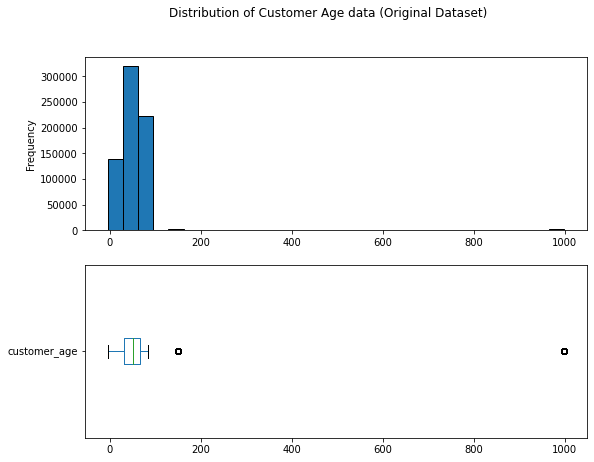

In [23]:
# See distribution of data in column

# Convert the customer_age column to numeric data type. Save in a variable.
age_values = pd.to_numeric(data_CustDBL['customer_age'].copy(), errors = 'coerce')

fig, ax = plt.subplots(2, 1, figsize = (9,7))
age_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
age_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle('Distribution of Customer Age data (Original Dataset)') ;


# Calculate the mean and standard deviation of main values
mean_val = age_values.mean()
st_dev = age_values.std()
st_dev = np.round(st_dev, 1)
mean_val = np.round(mean_val, 1)
median_value = age_values.quantile(0.5)
print("\nOn Original dataset before any assessment. . . . . . . .")
print(f"Standard deviation is: {st_dev}")
print(f"Mean is: {mean_val}")
print(f"Median is: {median_value}")

<ipython-input-24-bea0db92ddd1>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['customer_age'] = (data_CustDBL['customer_age']



On dataset after replacing outlier values in customer_age values. . . . . . . .
Standard deviation is: 20.5
Mean is: 49.5
Median is: 50.0


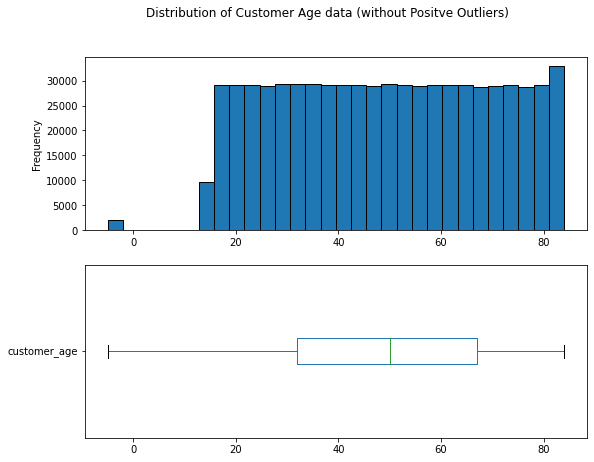

In [24]:
# The main dataset contains outliers
extract = data_CustDBL['customer_age'].copy() # Extract the data in the customer_age column.
extract = pd.to_numeric(extract, errors = 'coerce') # Convert the data in the extracted column to numeric.
extract.value_counts().sort_index(ascending = False) # Put in print statement to see output
# print("99th percentile is", extract.quantile(0.99))

# Handle the very high age values of 999 and 150.
# Replace them with the 99th percentile value.
data_CustDBL['customer_age'] = (data_CustDBL['customer_age']
                         .astype(str)
                         .str.replace(str(999), str(extract.quantile(0.99)))
                         .str.replace(str(150), str(extract.quantile(0.99)))
                         )

# See distribution of data in column without outliers
age_values = pd.to_numeric(data_CustDBL['customer_age'].copy(), errors = 'coerce')

fig, ax = plt.subplots(2, 1, figsize = (9,7))
age_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
age_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle('Distribution of Customer Age data (without Positve Outliers)') ;

# Calculate the mean and standard deviation after replacing outliers in customer_age.
mean_val = age_values.mean()
st_dev = age_values.std()
st_dev = np.round(st_dev, 1)
mean_val = np.round(mean_val, 1)
median_value = age_values.quantile(0.5)
print("\nOn dataset after replacing outlier values in customer_age values. . . . . . . .")
print(f"Standard deviation is: {st_dev}")
print(f"Mean is: {mean_val}")
print(f"Median is: {median_value}")

Non-Numeric Entries (Before Editing):  ['thirty' 'nan' 'old' 'forty-five' 'unknown']


C:\Users\ugoch\anaconda3\lib\site-packages\pandas\core\indexing.py:1676: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(ilocs[0], value, pi)


Non-Numeric Entries (After Editing):  ['30' nan '45']
Not-Numbers only (Before Editting):  ['30' nan '45' '-5' '18 years' '25+']
Not-Numbers only (After Editting):  ['30' 'nan' '45' nan '18']

After replacing thirty, forty-five, 25+, -5, 18 years, unknown, old, nan. . . . .
Standard deviation is: 20.3
Mean is: 49.5
Median is: 49.0


<ipython-input-25-24867b582b09>:101: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['customer_age'] = pd.to_numeric(data_CustDBL['customer_age'], errors = 'coerce')



After ALL replacements. . . . . . . . .
Standard deviation is: 20.3
Mean is: 49.5
Median is: 49.0


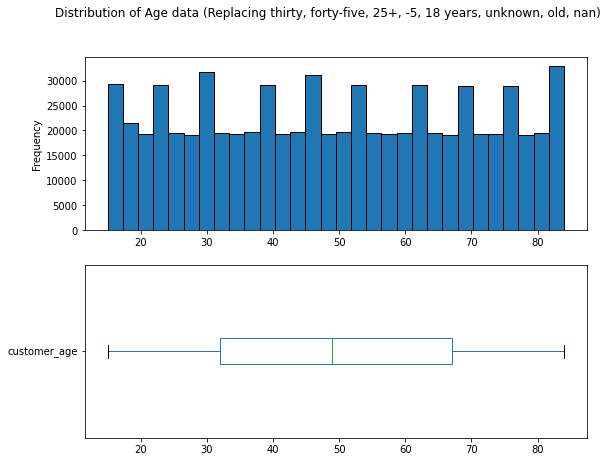

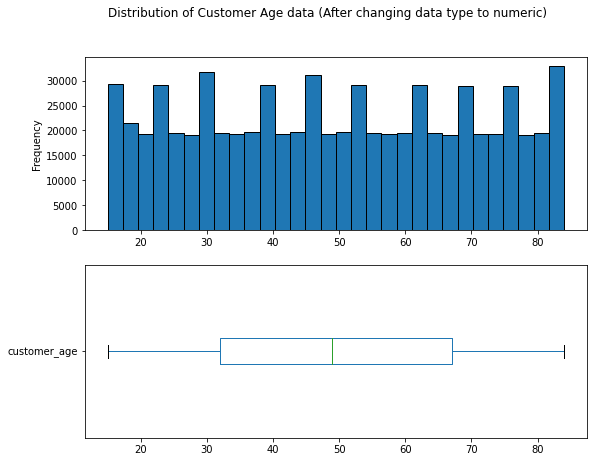

In [25]:
# Create masks
mask = (data_CustDBL['customer_age']
         .astype(str)
         .str.contains(r'[0-9]')
        ) # checks for the contents that are NUMBERS.

mask1 = ~mask # To check for contents that are NOT NUMBERS.

mask2 = (data_CustDBL['customer_age']
         .astype(str)
         .str.strip()
         .str.contains(r'[a-zA-Z \+\-]')
         
        ) # To check contents that don't contain only numbers

mask3 = (data_CustDBL['customer_age']
         .astype(str)
         .str.contains(r'\+|- ', regex = True)
        )

# mask2 = (mask2|mask3)



# ASSESSING THE customer_age COLUMN.


#1.
## VALUES THAT ARE NON-NUMERIC.

# BEFORE Editing
print("Non-Numeric Entries (Before Editing): ",data_CustDBL.loc[mask1, 'customer_age'].unique())


# Replace the word form of numbers.
data_CustDBL.loc[mask1, 'customer_age'] = (data_CustDBL.loc[mask1, 'customer_age']
                                           .astype(str)
                                           .replace('thirty', '30', regex = True)
                                           .replace('forty-five', '45', regex = True)
                                          )

# Replace 'unknown', 'old' with np.nan
data_CustDBL.loc[mask1, 'customer_age'] = (data_CustDBL.loc[mask1, 'customer_age']
                                           .astype(str)
                                           .replace('unknown', np.nan, regex = True)
                                           .replace('old', np.nan, regex = True)
                                           .replace('nan', np.nan, regex = True)
                                          )

# AFTER Editing
print("Non-Numeric Entries (After Editing): ",data_CustDBL.loc[mask1, 'customer_age'].unique())


#2.
# VALUES THAT DO NOT CONTAIN ONLY NUMBERS.


# BEFORE Editing.
print("Not-Numbers only (Before Editting): ",data_CustDBL.loc[mask2, 'customer_age'].unique())


# Replace the non-numeric characters.
data_CustDBL.loc[mask2, 'customer_age'] = (data_CustDBL.loc[mask2, 'customer_age']
                                           .astype(str)
                                           .replace('25+', np.nan, regex = True)
                                           .replace('18 years', '18', regex = True)
                                           .replace('-5', np.nan, regex = True)
                                          )

# AFTER Editing.
print("Not-Numbers only (After Editting): ",data_CustDBL.loc[mask2, 'customer_age'].unique())




# See distribution of data in column after replacing some non-numeric characters
age_values = pd.to_numeric(data_CustDBL['customer_age'].copy(), errors = 'coerce')
fig, ax = plt.subplots(2, 1, figsize = (9,7))
age_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
age_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle("Distribution of Age data (Replacing thirty, forty-five, 25+, -5, 18 years, unknown, old, nan)") ;


# Calculate the mean and standard deviation of remaining values
mean_val = age_values.mean()
st_dev = age_values.std()
st_dev = np.round(st_dev, 1)
mean_val = np.round(mean_val, 1)
median_value = age_values.quantile(0.5)
print("\nAfter replacing thirty, forty-five, 25+, -5, 18 years, unknown, old, nan. . . . .")
print(f"Standard deviation is: {st_dev}")
print(f"Mean is: {mean_val}")
print(f"Median is: {median_value}")






# Change the data type of the customer_age column
data_CustDBL['customer_age'] = pd.to_numeric(data_CustDBL['customer_age'], errors = 'coerce')



# See distribution of data in column After handling unclean values
age_values = pd.to_numeric(data_CustDBL['customer_age'].copy(), errors = 'coerce')
fig, ax = plt.subplots(2, 1, figsize = (9,7))
age_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
age_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle('Distribution of Customer Age data (After changing data type to numeric)') ;


# Calculate the mean and standard deviation of remaining values
mean_val = age_values.mean()
st_dev = age_values.std()
st_dev = np.round(st_dev, 1)
mean_val = np.round(mean_val, 1)
median_value = age_values.quantile(0.5)
print("\nAfter ALL replacements. . . . . . . . .")
print(f"Standard deviation is: {st_dev}")
print(f"Mean is: {mean_val}")
print(f"Median is: {median_value}")


### Income


On Original dataset before any assessment. . . . . . . .
Standard deviation is: 402163.7
Mean is: 71117.5
Median is: 54938.77315944483


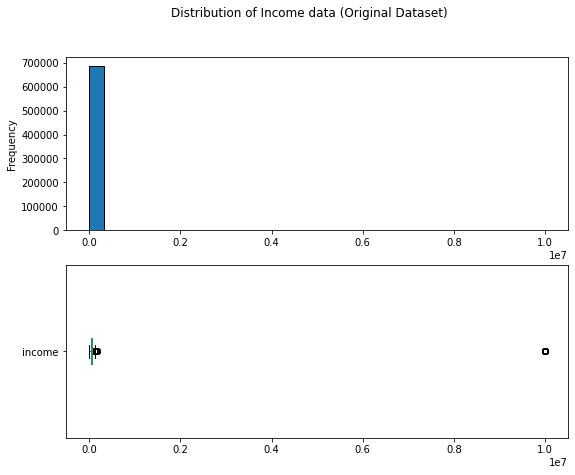

In [26]:
# See distribution of data in the column
income_values = pd.to_numeric(data_CustDBL['income'].copy(), errors = 'coerce')

fig, ax = plt.subplots(2, 1, figsize = (9,7))
income_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
income_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle('Distribution of Income data (Original Dataset)') ;


# Calculate the mean and standard deviation of remaining values
mean_val = income_values.mean()
st_dev = income_values.std()
st_dev = np.round(st_dev, 1)
mean_val = np.round(mean_val, 1)
median_value = income_values.quantile(0.5)
print("\nOn Original dataset before any assessment. . . . . . . .")
print(f"Standard deviation is: {st_dev}")
print(f"Mean is: {mean_val}")
print(f"Median is: {median_value}")

<ipython-input-27-1b23401a4e8e>:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['income'] = (data_CustDBL['income']



On Original dataset, AFTER HANDLING OUTLIER VALUES IN ORIGINAL DATASET. . . . . . . .
Standard deviation is: 45533.0
Mean is: 56432.5
Median is: 54938.77315944483


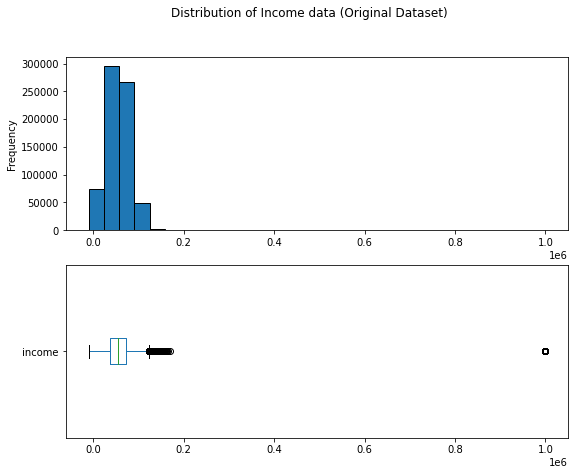

In [27]:
# ASSESSING THE income COLUMN

# The main dataset contains outliers
extract = data_CustDBL['income'].copy()
extract = pd.to_numeric(extract, errors = 'coerce')
extract.value_counts().sort_index(ascending = False) # Put in print statement to see output


# Handle the very high income value of 9999999.
# Yearly Income of 9999999 is rare but not impossible. 
# Value of 999999 is used to replace it while maintaining INCOME class.
data_CustDBL['income'] = (data_CustDBL['income']
                         .astype(str)
                         .replace('9999999', '999999')
                         )


# See distribution of data in the column
income_values = pd.to_numeric(data_CustDBL['income'].copy(), errors = 'coerce')

fig, ax = plt.subplots(2, 1, figsize = (9,7))
income_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
income_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle('Distribution of Income data (Original Dataset)') ;


# Calculate the mean and standard deviation of remaining values
mean_val = income_values.mean()
st_dev = income_values.std()
st_dev = np.round(st_dev, 1)
mean_val = np.round(mean_val, 1)
median_value = income_values.quantile(0.5)
print("\nOn Original dataset, AFTER HANDLING OUTLIER VALUES IN ORIGINAL DATASET. . . . . . . .")
print(f"Standard deviation is: {st_dev}")
print(f"Mean is: {mean_val}")
print(f"Median is: {median_value}")

Non-Numeric Entries (Before Editing):  ['nan' 'rich' 'zero' 'unknown' 'fifty thousand']
Non-Numeric Entries (After Editing):  [nan 'rich' '0' '50000']

Non-Numeric Entries (Before Editing):  [nan 'rich' '0' '50000']


C:\Users\ugoch\anaconda3\lib\site-packages\pandas\core\indexing.py:1676: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(ilocs[0], value, pi)


Non-Numeric Entries (After Editing):  [nan '293800' '0' '50000']

On Correcting NON-NUMERIC VALUES. . . . . .
Standard deviation is: 46518.8
Mean is: 56729.1
Median is: 54886.47878173976

Not-Numbers only (Before Editing):  ['100k+' '>200k' '45k' '$45,000' '-1' '-10000' nan]
Not-Numbers only (After Editting):  ['nan' '45000' nan]


C:\Users\ugoch\anaconda3\lib\site-packages\pandas\core\indexing.py:1720: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, value, pi)



After handling MIX OF NUMERIC AND NON-NUMERIC VALUES. . . . . . . .
Standard deviation is: 46381.6
Mean is: 56898.2
Median is: 54884.24038437556


<ipython-input-28-3fdec4a2c656>:174: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['income'] = pd.to_numeric(data_CustDBL['income'], errors = 'coerce')
<ipython-input-28-3fdec4a2c656>:177: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['income'] = np.round(data_CustDBL['income'], 2)



After handling ALL value tranforms. . . . . . . .
Standard deviation is: 46381.6
Mean is: 56898.2
Median is: 54884.240000000005


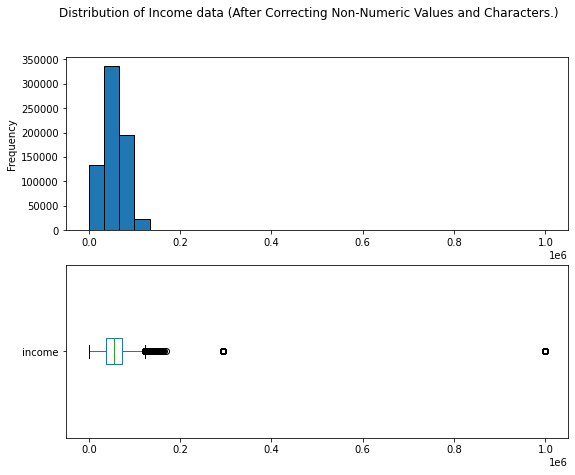

In [28]:
# Create masks
mask1 = (data_CustDBL['income']
         .astype(str)
         .str.contains(r'[0-9]')
        )

mask1 = ~mask1 # To check for contents that are NOT NUMBERS


mask2 = (data_CustDBL['income']
         .astype(str)
         .str.strip()
         .str.contains(r'[^0-9.]', regex = True)
        ) # To check contents that don't contain only numbers

mask3 = (data_CustDBL['income']
         .astype(str)
         .str.strip()
         .str.contains(r'[$,k>\-\+]')
        )

mask4 = (data_CustDBL['income']
         .astype(str)
         .str.strip()
         .str.contains(r'[-+>]', regex =True)
        )

mask5 = (data_CustDBL['income']
         .astype(str)
         .str.strip()
         .str.contains(r'[$,]', regex =True)
        )

mask6 = (data_CustDBL['income']
         .astype(str)
         .str.strip()
         .str.contains('k', regex =True)
        )



#1.
## VALUES THAT ARE NON-NUMERIC.


# BEFORE Editing
print("Non-Numeric Entries (Before Editing): ",data_CustDBL.loc[mask1, 'income'].unique())

# rich will be taken to be the top 1% of earners in Canada (293800 CAD annually)
# unknown will be replaced with null.
# zero will be represented as 0. AN INCOME CAN BE A ZERO value.


# Replace the word form of numbers.
data_CustDBL.loc[mask1, 'income'] = (data_CustDBL.loc[mask1, 'income']
                                           .astype(str)
                                           .replace('fifty thousand', '50000', regex = True)
                                           .replace('zero', '0', regex = True)
                                          )

# Replace 'unknown' with null
# Replace 'nan' with null
data_CustDBL.loc[mask1, 'income'] = (data_CustDBL.loc[mask1, 'income']
                                           .astype(str)
                                           .replace('unknown', np.nan, regex = True)
                                           .replace('nan', np.nan, regex = True)
                                          )

# AFTER Editing
print("Non-Numeric Entries (After Editing): ",data_CustDBL.loc[mask1, 'income'].unique())



#1. Continued. . . . . 
## VALUES THAT ARE NON-NUMERIC (Continued).
## To be statistically considered rich in Canada, an individual needs a minimum
## annual income of 293800 CAD ---- Google


# BEFORE Editing
print("\nNon-Numeric Entries (Before Editing): ",data_CustDBL.loc[mask1, 'income'].unique())

# Replace the word 'rich' with 293800, and 'nan' with null.
data_CustDBL.loc[mask1, 'income'] = (data_CustDBL.loc[mask1, 'income']
                                           .astype(str)
                                           .replace('rich', '293800', regex = True)
                                           .replace('nan', np.nan, regex = True)
                                          )

# AFTER Editing
print("Non-Numeric Entries (After Editing): ",data_CustDBL.loc[mask1, 'income'].unique())



# Calculate the mean and standard deviation of remaining values
income_values = pd.to_numeric(data_CustDBL['income'].copy(), errors = 'coerce')
mean_val = income_values.mean()
st_dev = income_values.std()
st_dev = np.round(st_dev, 1)
mean_val = np.round(mean_val, 1)
median_value = income_values.quantile(0.5)
print("\nOn Correcting NON-NUMERIC VALUES. . . . . .")
print(f"Standard deviation is: {st_dev}")
print(f"Mean is: {mean_val}")
print(f"Median is: {median_value}")



#2.
## VALUES THAT DO NOT CONTAIN ONLY NUMBERS.


# BEFORE Editing.
print("\nNot-Numbers only (Before Editing): ",data_CustDBL.loc[mask3, 'income'].unique())

# Replace $ and , with nothing.
# For values have + and/or >, replace with null

# Replace the characters in the numbers.
# data_CustDBL.loc[mask3, 'income'] = (data_CustDBL.loc[mask3, 'income']
#                                         .astype(str)
#                                         .replace(r'[$,]', '', regex = True)
#                                         .replace(r'[45k, $45,000]', '45000', regex = True)
#                                         .replace(r'[100k+, >200k]', np.nan, regex = True)
#                                         .replace(r'[-1, -10000, nan]', np.nan, regex = True)
#                                         )

# Not-Numbers only (Before Editing):  ['100k+' '>200k' '45k' '$45,000' '-1' '-10000' nan]

data_CustDBL.loc[mask4,'income'] = np.nan

data_CustDBL.loc[mask5,'income'] = (data_CustDBL.loc[mask5,'income']
                                    .astype(str)
                                    .replace(r'[$,]', '', regex = True)
                                    #.replace('$45,000', '45000', regex = True)
                                    #.replace('45k', '45000', regex = True)
                                    #.replace(r'[100k+, >200k]', np.nan, regex = True)
                                    #.replace(r'[-1, -10000, nan]', np.nan, regex = True)
                                        )

data_CustDBL.loc[mask6,'income'] = (data_CustDBL.loc[mask6,'income']
                                    .astype(str)
                                    .replace('k', '000', regex = True)
                                    )


# AFTER Editing.
print("Not-Numbers only (After Editting): ",data_CustDBL.loc[mask3, 'income'].unique())


# See distribution of data in the column AFTER EDITING NUMBER REPRESENTATIONS
income_values = pd.to_numeric(data_CustDBL['income'].copy(), errors = 'coerce')
fig, ax = plt.subplots(2, 1, figsize = (9,7))
income_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
income_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle('Distribution of Income data (After Correcting Non-Numeric Values and Characters.)') ;



# Calculate the mean and standard deviation of remaining values
income_values = pd.to_numeric(data_CustDBL['income'].copy(), errors = 'coerce')
mean_val = income_values .mean()
st_dev = income_values .std()
st_dev = np.round(st_dev, 1)
mean_val = np.round(mean_val, 1)
median_value = income_values.quantile(0.5)
print("\nAfter handling MIX OF NUMERIC AND NON-NUMERIC VALUES. . . . . . . .")
print(f"Standard deviation is: {st_dev}")
print(f"Mean is: {mean_val}")
print(f"Median is: {median_value}")


# Change the data type of the income column
data_CustDBL['income'] = pd.to_numeric(data_CustDBL['income'], errors = 'coerce')

# Change the number of decimal places of values in income column.
data_CustDBL['income'] = np.round(data_CustDBL['income'], 2)

# Calculate the mean and standard deviation of final set of values
income_values = pd.to_numeric(data_CustDBL['income'].copy(), errors = 'coerce')
mean_val = income_values .mean()
st_dev = income_values .std()
st_dev = np.round(st_dev, 1)
mean_val = np.round(mean_val, 1)
median_value = income_values.quantile(0.5)
print("\nAfter handling ALL value tranforms. . . . . . . .")
print(f"Standard deviation is: {st_dev}")
print(f"Mean is: {mean_val}")
print(f"Median is: {median_value}")

In [29]:
# Outpit datadrame information
data_CustDBL.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 700000 entries, 0 to 734998
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   order_id            700000 non-null  int64  
 1   date_of_purchase    693002 non-null  object 
 2   customer_age        689485 non-null  float64
 3   gender              700000 non-null  object 
 4   marital_status      700000 non-null  object 
 5   income              692992 non-null  float64
 6   educational_level   700000 non-null  object 
 7   occupation          700000 non-null  object 
 8   product_category    700000 non-null  object 
 9   type_of_bike        700000 non-null  object 
 10  commute_distance    700000 non-null  object 
 11  home_ownership      700000 non-null  object 
 12  number_of_cars      700000 non-null  object 
 13  number_of_children  700000 non-null  object 
 14  purchased_or_not    700000 non-null  object 
dtypes: float64(2), int64(1), object(12

### Number of Cars

 99.0      1965
 5.0      12724
 4.0      32320
 3.0      86148
 2.0     171981
 1.0     229526
 0.0     153301
-1.0       1961
Name: number_of_cars, dtype: int64


unknown      1975
several      2034
none         2038
nan          2016
many         2011
99           1965
5           12724
4           32320
3           86148
2          171981
1          229526
0          153301
-1           1961
Name: number_of_cars, dtype: int64
lower limit is 0.0 and upper limit is 3.0. Median is 1.0



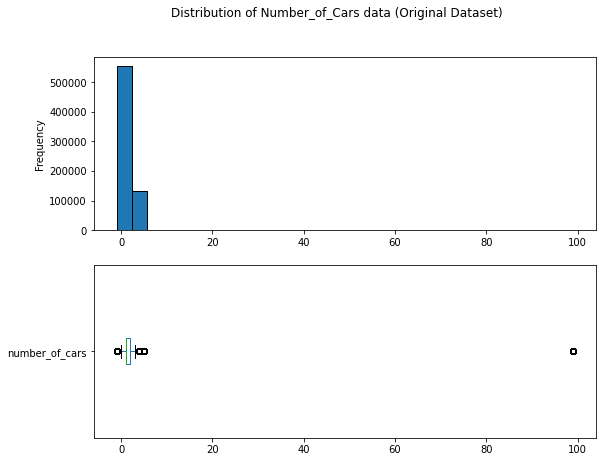

In [30]:
# See distribution of data in the column
cars_values = pd.to_numeric(data_CustDBL['number_of_cars'].copy(), errors = 'coerce')

fig, ax = plt.subplots(2, 1, figsize = (9,7))
cars_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
cars_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle('Distribution of Number_of_Cars data (Original Dataset)') ;


# The main dataset contains what ?
extract = data_CustDBL['number_of_cars'].copy()
extract = pd.to_numeric(extract, errors = 'coerce')
print(extract.value_counts().sort_index(ascending = False)) # Put in print statement to see output
print('\n')
print((data_CustDBL['number_of_cars'].value_counts().sort_index(ascending = False)))

Q1 = extract.quantile(0.25)
Q2 = extract.quantile(0.5)
Q3 = extract.quantile(0.75)

lower_limit = Q1 - (Q3 - Q1)
upper_limit = Q3 + (Q3 - Q1)

print(f'lower limit is {lower_limit} and upper limit is {upper_limit}. Median is {Q1}\n')


99th percentile value is 5.0



<ipython-input-31-68d7c4a87081>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['number_of_cars'] = (data_CustDBL['number_of_cars']


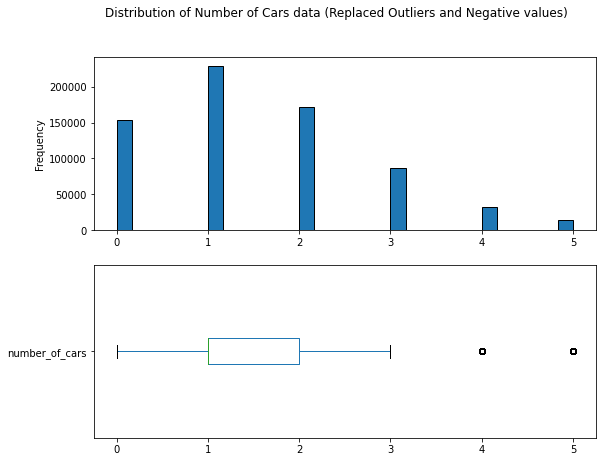

In [31]:
# Handle the very high income value of 99
# Calculate the 99th percentile and use it to replace the outlier value of 99
# Replace value of -1 with null.

median_value = extract.median()
y99th_percentile = extract.quantile(0.99)
print(f'\n99th percentile value is {y99th_percentile}\n')
data_CustDBL['number_of_cars'] = (data_CustDBL['number_of_cars']
                         .astype(str)
                         .replace('99', str(int(y99th_percentile)))
                         .replace('-1', np.nan, regex = True)
                        )



# See distribution of data in the column
cars_values = pd.to_numeric(data_CustDBL['number_of_cars'].copy(), errors = 'coerce')

fig, ax = plt.subplots(2, 1, figsize = (9,7))
cars_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
cars_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle('Distribution of Number of Cars data (Replaced Outliers and Negative values)') ;

Non-Numeric Entries (Before Editing):  ['nan' 'none' 'many' nan 'unknown' 'several']
Non-Numeric Entries (After Editing):  ['nan' '0' 'many' nan 'unknown' '3']


C:\Users\ugoch\anaconda3\lib\site-packages\pandas\core\indexing.py:1676: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(ilocs[0], value, pi)


Not-Numbers only (Before Editting):  ['1' '2' '3' '0' 'nan' '4' 'many' '5' nan 'unknown']
Not-Numbers only (After Editing):  ['1' '2' '3' '0' nan '4' '5']


<ipython-input-32-5b1ec9bd5b40>:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['number_of_cars'] = pd.to_numeric(data_CustDBL['number_of_cars'], errors = 'coerce')


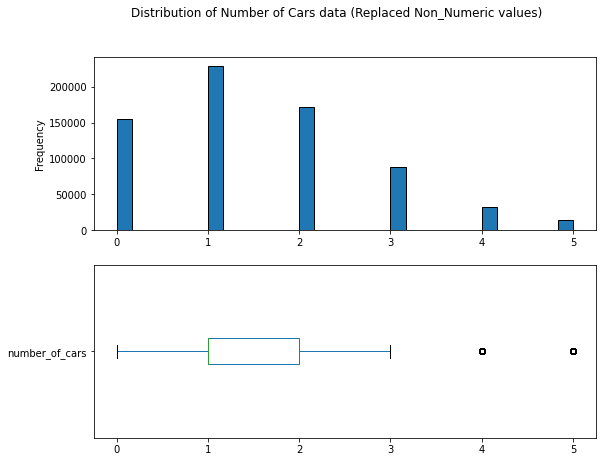

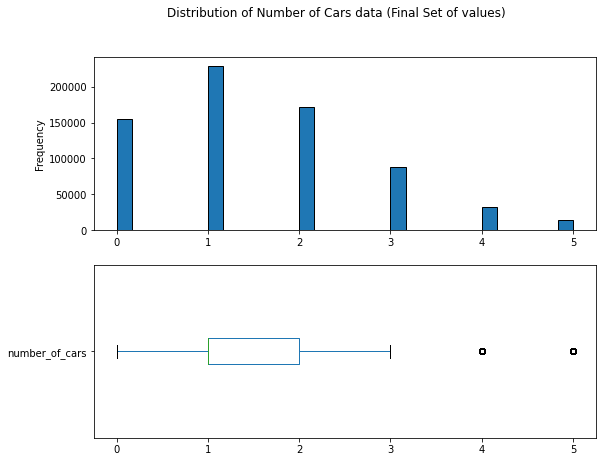

In [32]:
# Create masks
mask1 = (data_CustDBL['number_of_cars']
         .astype(str)
         .str.contains(r'[0-9]')
        )

mask1 = ~mask1 # To check for contents that are NOT NUMBERS


mask2 = (data_CustDBL['number_of_cars']
         .astype(str)
         .str.strip()
         .str.contains(r'[0-9a-zA-Z.]', regex = True)
        ) # To check contents that don't contain only numbers


#1.
## VALUES THAT ARE NON-NUMERIC.


# BEFORE Editing
print("Non-Numeric Entries (Before Editing): ",data_CustDBL.loc[mask1, 'number_of_cars'].unique()) 

# 1-2 cars: Usually referred to as a "few" or a "couple"
# 3-4 cars: Commonly accepted as "several" in general or practical terms
# 5 or more cars: Often translates to "many" or a "fleet". This is NOT SPECIFIC.
# Therfore "many" will be replaced with null.

# In the dataset, several has 2034 data points, 3 has 86148 data points and
# 4 has 32320 data points. 
# Replacing several with 3 will add a 2.34% increase in the data points of 3.

# Create mapping
mapping_number_of_cars = {
            'unknown': np.nan,   'none':'0',   'many':np.nan,   'several':'3',
            'nan' : np.nan
}

# Apply mapping
data_CustDBL.loc[mask1, 'number_of_cars'] = (data_CustDBL.loc[mask1, 'number_of_cars']
                                            .map(mapping_number_of_cars)
                                            .fillna(data_CustDBL.loc[mask1, 'number_of_cars'])
                                            )

# AFTER Editing
print("Non-Numeric Entries (After Editing): ",data_CustDBL.loc[mask1, 'number_of_cars'].unique())




#2.
# VALUES THAT DO NOT CONTAIN ONLY NUMBERS.


# BEFORE Editing.
print("Not-Numbers only (Before Editting): ",data_CustDBL.loc[mask2, 'number_of_cars'].unique())


# Create mapping
mapping_number_of_cars = {
            'unknown': np.nan,  'nan' : np.nan
}

# Apply mapping
data_CustDBL.loc[mask1, 'number_of_cars'] = (data_CustDBL.loc[mask2, 'number_of_cars']
                                            .map(mapping_number_of_cars)
                                            .fillna(data_CustDBL.loc[mask2, 'number_of_cars'])
                                            )
data_CustDBL.loc[mask1, 'number_of_cars'] = (data_CustDBL.loc[mask2, 'number_of_cars']
                                             .astype(str)
                                             .replace(r'[unknown, nan]', np.nan, regex = True)
                                            )

# AFTER Editing
print("Not-Numbers only (After Editing): ",data_CustDBL.loc[mask2, 'number_of_cars'].unique())




# See distribution of data in the column
cars_values = pd.to_numeric(data_CustDBL['number_of_cars'].copy(), errors = 'coerce')
fig, ax = plt.subplots(2, 1, figsize = (9,7))
cars_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
cars_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle('Distribution of Number of Cars data (Replaced Non_Numeric values)') ;



# Change the data type of the number_of_cars column
data_CustDBL['number_of_cars'] = pd.to_numeric(data_CustDBL['number_of_cars'], errors = 'coerce')

# Calculate the median value
median_value = data_CustDBL['number_of_cars'].median()


# See distribution of data in the column
cars_values = pd.to_numeric(data_CustDBL['number_of_cars'].copy(), errors = 'coerce')
fig, ax = plt.subplots(2, 1, figsize = (9,7))
cars_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
cars_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle('Distribution of Number of Cars data (Final Set of values)') ;


### Number of Children

unknown      2093
twins        1974
none         1987
nan          2013
many         1991
6             114
50           1985
5             788
4            5309
3           26594
2           98586
1          246361
0          308248
-5           1957
Name: number_of_children, dtype: int64
lower limit is -1.0 and upper limit is 2.0. Median is 1.0



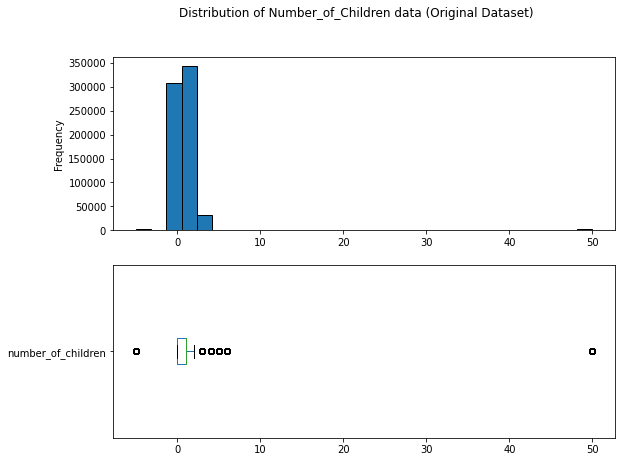

In [33]:
# See distribution of data in the column
childre_values = pd.to_numeric(data_CustDBL['number_of_children'].copy(), errors = 'coerce')

fig, ax = plt.subplots(2, 1, figsize = (9,7))
childre_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
childre_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle('Distribution of Number_of_Children data (Original Dataset)') ;


# The main dataset contains what ?
extract = data_CustDBL['number_of_children'].copy()
extract = pd.to_numeric(extract, errors = 'coerce')
extract.value_counts().sort_index(ascending = False) # Put in print statement to see output
print(data_CustDBL['number_of_children'].copy().value_counts().sort_index(ascending = False))


Q1 = extract.quantile(0.25)
Q2 = extract.quantile(0.5)
Q3 = extract.quantile(0.75)

lower_limit = Q1 - (Q3 - Q1)
upper_limit = Q3 + (Q3 - Q1)

print(f'lower limit is {lower_limit} and upper limit is {upper_limit}. Median is {Q2}\n')

Non-Numeric Entries (Before Editing):  ['many' 'twins' 'nan' 'unknown' 'none']
Non-Numeric Entries (After Editing):  [nan '2' '0']


C:\Users\ugoch\anaconda3\lib\site-packages\pandas\core\indexing.py:1676: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(ilocs[0], value, pi)


6        114
50      1985
5        788
4       5309
3      26594
2     100560
1     246361
0     310235
-5      1957
Name: number_of_children, dtype: int64

After correcting the entry value of many, twins, none, unknown and nan.....

lower limit is -1.0 and upper limit is 2.0. Median is 1.0



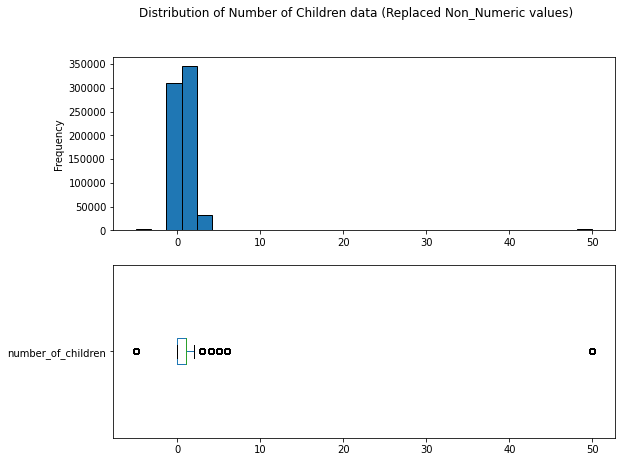

In [34]:
# Create masks
mask1 = (data_CustDBL['number_of_children']
         .astype(str)
         .str.contains(r'[0-9]')
        )

mask1 = ~mask1 # To check for contents that are NOT NUMBERS


mask2 = (data_CustDBL['number_of_children']
         .astype(str)
         .str.strip()
         .str.contains(r'[^0-9.]', regex = True)
        ) # To check contents that don't contain only numbers


#1.
## VALUES THAT ARE NON-NUMERIC.


# BEFORE Editting
print("Non-Numeric Entries (Before Editing): ",data_CustDBL.loc[mask1, 'number_of_children'].unique()) 

# Linguistically and Culturally, the minimum number that represents "many" is generally 4 children
# Google search engine. . . . 5th July 2026. There is however NO DEFINITE VALUE.

mapping_number_of_children = {
    'many':np.nan,   'twins':'2',   'none':'0',   'unknown':np.nan,
    'nan':np.nan
}

# Apply mapping
data_CustDBL.loc[mask1, 'number_of_children'] = (data_CustDBL.loc[mask1, 'number_of_children']
                                            .map(mapping_number_of_children)
                                            .fillna(data_CustDBL.loc[mask1, 'number_of_children'])
                                            )

data_CustDBL.loc[mask1, 'number_of_children'] = (data_CustDBL.loc[mask1, 'number_of_children']
                                                 .astype(str)
                                                 .replace(r'[unknown, nan]', np.nan, regex = True)
                                                )

# AFTER Editting
print("Non-Numeric Entries (After Editing): ",data_CustDBL.loc[mask1, 'number_of_children'].unique())




# See distribution of data in the column
children_values = pd.to_numeric(data_CustDBL['number_of_children'].copy(), errors = 'coerce')
fig, ax = plt.subplots(2, 1, figsize = (9,7))
children_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
children_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle('Distribution of Number of Children data (Replaced Non_Numeric values)') ;



# After correcting the non numerical entries ?
extract = pd.to_numeric(data_CustDBL['number_of_children'].copy(), errors = 'coerce')
extract = pd.to_numeric(extract, errors = 'coerce')
extract.value_counts().sort_index(ascending = False) # Put in print statement to see output
print(data_CustDBL['number_of_children'].copy().value_counts().sort_index(ascending = False))


Q1 = extract.quantile(0.25)
Q2 = extract.quantile(0.5)
Q3 = extract.quantile(0.75)

lower_limit = Q1 - (Q3 - Q1)
upper_limit = Q3 + (Q3 - Q1)

print("\nAfter correcting the entry value of many, twins, none, unknown and nan.....\n")
print(f'lower limit is {lower_limit} and upper limit is {upper_limit}. Median is {Q2}\n')

Median value is 1.0


<ipython-input-35-36a718d374e2>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['number_of_children'] = (data_CustDBL['number_of_children']


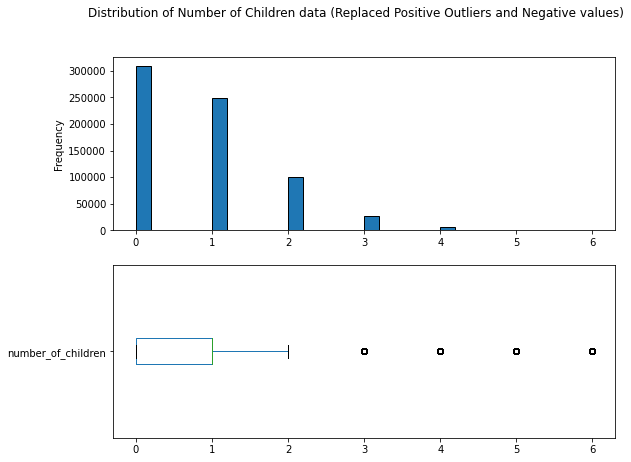

In [35]:
# Handle the very high number of children value of 50 and negative value of -5.
# Replace the value of 50 (1985 data points) with 1 (~0.4% increase).
# Replace the value of -5 (1957 data points) with null.

median_value = extract.median()
print(f'Median value is {median_value}')
data_CustDBL['number_of_children'] = (data_CustDBL['number_of_children']
                         .astype(str)
                         .replace('50', str(median_value))
                         .replace('-5', np.nan, regex = True)
                        )


# See distribution of data in the column
children_values = pd.to_numeric(data_CustDBL['number_of_children'].copy(), errors = 'coerce')
fig, ax = plt.subplots(2, 1, figsize = (9,7))
children_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
children_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle('Distribution of Number of Children data (Replaced Positive Outliers and Negative values)') ;

<ipython-input-36-1584d3b8003f>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['number_of_children'] = pd.to_numeric(data_CustDBL['number_of_children'], errors = 'coerce')


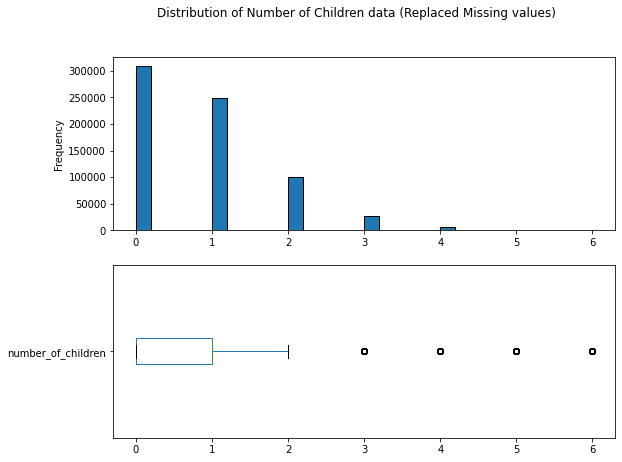

In [36]:
# Change the data type of the number_of_cars column
data_CustDBL['number_of_children'] = pd.to_numeric(data_CustDBL['number_of_children'], errors = 'coerce')


# See distribution of data in the column
children_values = pd.to_numeric(data_CustDBL['number_of_children'].copy(), errors = 'coerce')
fig, ax = plt.subplots(2, 1, figsize = (9,7))
children_values.plot(kind = 'hist', edgecolor = 'black', bins = 30, ax=ax[0])
children_values.plot(kind = 'box', vert = False, ax=ax[1])
plt.suptitle('Distribution of Number of Children data (Replaced Missing values)') ;

In [37]:
data_CustDBL.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 700000 entries, 0 to 734998
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   order_id            700000 non-null  int64  
 1   date_of_purchase    693002 non-null  object 
 2   customer_age        689485 non-null  float64
 3   gender              700000 non-null  object 
 4   marital_status      700000 non-null  object 
 5   income              692992 non-null  float64
 6   educational_level   700000 non-null  object 
 7   occupation          700000 non-null  object 
 8   product_category    700000 non-null  object 
 9   type_of_bike        700000 non-null  object 
 10  commute_distance    700000 non-null  object 
 11  home_ownership      700000 non-null  object 
 12  number_of_cars      692037 non-null  float64
 13  number_of_children  691946 non-null  float64
 14  purchased_or_not    700000 non-null  object 
dtypes: float64(4), int64(1), object(10

# Date

In [38]:
data_CustDBL['date_of_purchase'] = pd.to_datetime(data_CustDBL['date_of_purchase'], errors = 'coerce').dt.normalize()
data_CustDBL.info()

<ipython-input-38-395e68871287>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_CustDBL['date_of_purchase'] = pd.to_datetime(data_CustDBL['date_of_purchase'], errors = 'coerce').dt.normalize()


<class 'pandas.core.frame.DataFrame'>
Int64Index: 700000 entries, 0 to 734998
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   order_id            700000 non-null  int64         
 1   date_of_purchase    692822 non-null  datetime64[ns]
 2   customer_age        689485 non-null  float64       
 3   gender              700000 non-null  object        
 4   marital_status      700000 non-null  object        
 5   income              692992 non-null  float64       
 6   educational_level   700000 non-null  object        
 7   occupation          700000 non-null  object        
 8   product_category    700000 non-null  object        
 9   type_of_bike        700000 non-null  object        
 10  commute_distance    700000 non-null  object        
 11  home_ownership      700000 non-null  object        
 12  number_of_cars      692037 non-null  float64       
 13  number_of_children  691946 no

In [39]:
# Make a copy of the dataframe
data_CustDBL_copy = data_CustDBL.copy()

# Reset index and fill the missing dates
data_CustDBL_copy = data_CustDBL_copy.reset_index()
data_CustDBL_copy = data_CustDBL_copy.drop(columns = ['index'])
data_CustDBL_copy['date_of_purchase'] = data_CustDBL_copy['date_of_purchase'].ffill()

# Create another copy of the dataframe
data_CustDBL_copy_drop_dates = data_CustDBL.copy()
data_CustDBL_copy_drop_dates = data_CustDBL_copy_drop_dates.dropna(subset = ['date_of_purchase'])
data_CustDBL_copy_drop_dates = data_CustDBL_copy_drop_dates.reset_index()
data_CustDBL_copy_drop_dates = data_CustDBL_copy_drop_dates.drop(columns = 'index')
data_CustDBL_copy_drop_dates


,order_id,date_of_purchase,customer_age,gender,marital_status,income,educational_level,occupation,product_category,type_of_bike,commute_distance,home_ownership,number_of_cars,number_of_children,purchased_or_not
0,562534,2021-10-11,30.0,Non-Binary,Married,64720.27,Bachelors,Manager,Bikes,Sports,Unknown,Unknown,1.0,2.0,Yes
1,94346,2024-03-13,42.0,Male/He/Him/Man,Single,54224.76,High School/GED,Unemployed,Accessories,Unknown,3-5 Miles,Owner/Outright Owner,2.0,0.0,Yes
2,37446,2021-04-05,60.0,Female/She/Her/Woman,Widowed,80926.50,School Leaver,Unknown,Bikes,Mountain,Unspecified,Mortgage,3.0,1.0,No
3,354279,2025-01-24,50.0,Female/She/Her/Woman,Divorced,8929.26,Masters,Nurse,Accessories,Unknown,Unknown,Other,1.0,1.0,Yes
4,515537,2021-02-15,42.0,Unknown,Single,62573.43,Bachelors,Engineer,Bikes,Road,Unknown,Unknown,0.0,0.0,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
692817,235385,2020-06-07,82.0,Female/She/Her/Woman,Married,46571.14,Bachelors,Unknown,Bikes,Mountain,Unknown,Tenant,1.0,1.0,No
692818,382795,2022-06-01,63.0,Female/She/Her/Woman,Divorced,66775.17,Unknown,Sales,Part,Unknown,Unknown,Other,1.0,0.0,No
692819,261778,2025-06-24,45.0,Female/She/Her/Woman,Separated,21651.34,Elementary,Engineer,Other,Unknown,Unknown,Tenant,1.0,1.0,No
692820,306747,2021-07-24,27.0,Male/He/Him/Man,Unknown,60020.49,School Leaver,Teacher,Bikes,E-Bike,Unspecified,Tenant,1.0,0.0,No


In [40]:
data_CustDBL_copy

,order_id,date_of_purchase,customer_age,gender,marital_status,income,educational_level,occupation,product_category,type_of_bike,commute_distance,home_ownership,number_of_cars,number_of_children,purchased_or_not
0,562534,2021-10-11,30.0,Non-Binary,Married,64720.27,Bachelors,Manager,Bikes,Sports,Unknown,Unknown,1.0,2.0,Yes
1,94346,2024-03-13,42.0,Male/He/Him/Man,Single,54224.76,High School/GED,Unemployed,Accessories,Unknown,3-5 Miles,Owner/Outright Owner,2.0,0.0,Yes
2,37446,2021-04-05,60.0,Female/She/Her/Woman,Widowed,80926.50,School Leaver,Unknown,Bikes,Mountain,Unspecified,Mortgage,3.0,1.0,No
3,354279,2025-01-24,50.0,Female/She/Her/Woman,Divorced,8929.26,Masters,Nurse,Accessories,Unknown,Unknown,Other,1.0,1.0,Yes
4,515537,2021-02-15,42.0,Unknown,Single,62573.43,Bachelors,Engineer,Bikes,Road,Unknown,Unknown,0.0,0.0,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699995,235385,2020-06-07,82.0,Female/She/Her/Woman,Married,46571.14,Bachelors,Unknown,Bikes,Mountain,Unknown,Tenant,1.0,1.0,No
699996,382795,2022-06-01,63.0,Female/She/Her/Woman,Divorced,66775.17,Unknown,Sales,Part,Unknown,Unknown,Other,1.0,0.0,No
699997,261778,2025-06-24,45.0,Female/She/Her/Woman,Separated,21651.34,Elementary,Engineer,Other,Unknown,Unknown,Tenant,1.0,1.0,No
699998,306747,2021-07-24,27.0,Male/He/Him/Man,Unknown,60020.49,School Leaver,Teacher,Bikes,E-Bike,Unspecified,Tenant,1.0,0.0,No


In [41]:
# Create the csv files for each
data_CustDBL_copy.to_csv("data_CustDBL_copy_filled_missing_dates.csv")
data_CustDBL_copy_drop_dates.to_csv("data_CustDBL_copy_dropped_missing_dates.csv")

In [42]:
# Create file of ONLY CUSTOMER INFORMATION
customers_dataset = data_CustDBL.drop(columns = ['product_category', 'type_of_bike'])
customers_dataset.to_csv("customers_dataset.csv")


In [43]:
# Determine the number of nulls in each field of the CUSTOMERS INFORMATION
# dataset

dataframe_access(customers_dataset)

,Data Types,Missing Cells,Missing Cells (%)
customer_age,float64,10515,1.50
number_of_children,float64,8054,1.15
number_of_cars,float64,7963,1.14
date_of_purchase,datetime64[ns],7178,1.03
income,float64,7008,1.00
order_id,int64,0,0.00
gender,object,0,0.00
marital_status,object,0,0.00
educational_level,object,0,0.00
occupation,object,0,0.00
